## Instalando pacotes

In [ ]:
!apt-get update -qq
!apt-get install -y openslide-tools libopenslide0

In [ ]:
!pip install openslide-python
!pip install kfbslide

## Setup

In [1]:
import json
import uuid
import os
import time
import numpy as np
import pandas as pd
from pathlib import Path

import openslide, kfbslide

from skimage.filters import threshold_otsu
from skimage.color import rgb2hsv

import torch
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2
from torchvision.io import decode_image

In [2]:
from google.colab import drive
drive.mount('/content/drive')

base_dir = "/content/drive/MyDrive/Lucas"

Mounted at /content/drive


## Extração de tiles

In [ ]:
def extract_tiles(slide_path, save_path, tile_size=224):
    # Abertura da lâmina e verificação de magnificação 20x
    s = kfbslide.OpenSlide(Path(slide_path))
    if int(s.properties.get("openslide.objective-power")) != 40:
        s.close()
        return
    if int(s.level_downsamples[1]) != 2:
        s.close()
        return

    # Otsu na lâmina toda (miniatura)
    lv_thumb = s.get_best_level_for_downsample(32)
    thumb = s.read_region((0, 0), lv_thumb, s.level_dimensions[lv_thumb]).convert("L")
    thr = threshold_otsu(np.asarray(thumb))
    total_area = tile_size * tile_size

    # Pasta de saída
    out_dir = Path(save_path)
    out_dir.mkdir(parents=True, exist_ok=True)

    # Extração de tiles
    level = 1
    step = tile_size * 2
    W, H = s.dimensions
    count = 0
    for y in range(0, H-step+1, step):
        for x in range(0, W-step+1, step):

            region = s.read_region((x, y), level, (tile_size, tile_size))
            if np.asarray(region)[..., 3].min() == 0:
                continue
            img = region.convert("RGB")

            gray = np.asarray(img.convert("L"))
            mask = gray < thr

            cell_area = mask.sum()
            if (cell_area / total_area) < 0.20:
              continue

            # Evita tiles 'sujos'
            px = np.asarray(img)[mask].reshape(-1, 1, 3)
            if np.median(rgb2hsv(px / 255.0)[..., 0]) * 360 < 180:
              continue

            img.save(out_dir / (str(count) + f"_{x}_{y}" + ".png"))
            count += 1

    s.close()

In [34]:
slide_name = "2024-10-14_08_20_41CYT"         # Troque aqui o nome da lâmina
slide_path = base_dir + "/" + slide_name + ".kfb"
save_path = base_dir + "/Slides/" + slide_name
local_path = '/content' + "/" + slide_name

if not os.path.exists(save_path):
  os.makedirs(save_path)
  extract_tiles(slide_path, save_path)
else:
  print("Extração de tiles já feita")

Extração de tiles já feita


## Copiando pasta para o ambiente de execução

In [ ]:
import shutil

shutil.copytree(save_path, local_path, dirs_exist_ok=True)

'/content/2024-10-14_08_34_52CYT'

In [ ]:
total = sum(
    len(arquivos)
    for _, _, arquivos in os.walk(save_path)
)
total_amb = sum(
    len(arquivos)
    for _, _, arquivos in os.walk(local_path)
)

print(f"Total de tiles (drive): {total}")
print(f"Total de tiles (amb): {total_amb}")

if total_amb != total:
  raise Exception(f"Total de tiles do ambiente de execução difere do drive")
else:
  print("Quantidade de tiles igual entre drive e ambiente de execução")

Total de tiles (drive): 4679
Total de tiles (amb): 4679
Quantidade de tiles igual entre drive e ambiente de execução


## Carregando tiles como dataset

In [35]:
tiles_names = []
sorted(tiles_names)
for arquivo in os.listdir(save_path):
  tiles_names.append(str(arquivo))

tiles_annotation = pd.DataFrame(sorted(tiles_names, key=lambda x: int(x.split("_")[0])))
tiles_annotation

,0
0,0_42112_0.png
1,1_41216_1344.png
2,2_41664_1344.png
3,3_42112_1344.png
4,4_43008_1344.png
...,...
8793,8793_45248_77504.png
8794,8794_45696_77504.png
8795,8795_46144_77504.png
8796,8796_46592_77504.png


In [ ]:
class Tiles_raw(Dataset):
    def __init__(self, annotations, img_dir, transform=None):
        self.annotations = annotations
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.annotations)

    def __getitem__(self, idx):
        img_path = self.img_dir + "/" + self.annotations.iloc[idx][0]
        image = decode_image(img_path)
        if self.transform:
            image = self.transform(image)
        return image

In [ ]:
transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True), v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])])

tiles_raw_dataset = Tiles_raw(tiles_annotation, local_path, transform)
tiles_raw_dataloader = DataLoader(tiles_raw_dataset, batch_size=64)

## Carregando UniCAS

In [ ]:
'''
Créditos: https://github.com/peter-fei/UniCAS
'''
import functools
import torch
import timm

# Define UniCAS parameters
params = {
    'patch_size': 16,
    'embed_dim': 1024,
    'depth': 24,
    'num_heads': 16,
    'init_values': 1e-5,
    'mlp_ratio': 2.671875 * 2,
    'mlp_layer': functools.partial(timm.layers.mlp.GluMlp, gate_last=False),
    'act_layer': torch.nn.SiLU,
    'no_embed_class': False,
    'img_size': 224,
    'num_classes': 0,
    'in_chans': 3,
}

# Build model
backbone = timm.models.VisionTransformer(**params)

# Load checkpoint
# Ensure 'UniCAS.pth' is in your current directory
state = torch.load(base_dir + "/" + "UniCAS.pth", map_location='cpu')
print(backbone.load_state_dict(state, strict=False))

# Inference example
backbone.eval()
if torch.cuda.is_available():
    backbone = backbone.cuda()

with torch.no_grad():
    # Input: [Batch, Channels, Height, Width]
    x = torch.randn(1, 3, 224, 224)
    if torch.cuda.is_available():
        x = x.cuda()
    out = backbone(x)
    print('Output feature shape:', out.shape) # Expected: [1, 1024]

<All keys matched successfully>
Output feature shape: torch.Size([1, 1024])


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
for param in backbone.parameters():
    param.requires_grad = False

## Extração de embeddings dos tiles com UniCAS

In [ ]:
backbone = backbone.to(device)

embeddings = []
with torch.no_grad():
  for X in tiles_raw_dataloader:
    X = X.to(device)
    embedding = backbone(X)
    embeddings.append(embedding.cpu())

torch_embeddings = torch.cat(embeddings, dim=0)
torch.save(torch_embeddings, base_dir + "/Embeddings/" +"embeddings_" + slide_name + ".pt")

In [36]:
torch_embeddings = torch.load(base_dir + "/Embeddings/" + "embeddings_" + slide_name + ".pt")
torch_embeddings.shape

torch.Size([8798, 1024])

## Carregando ambil.pth (treinado sobre o BMT, com UniCAS como backbone)

In [37]:
'''
Feito com auxílio do  Claude Code (Opus 5.5 / High)
'''

import torch.nn as nn

class GatedAttentionMIL(nn.Module):
    """ABMIL com atenção com porta (Ilse et al., 2018)."""

    def __init__(self, in_dim=1024, hid=256, att_hid=128, n_classes=3, p_drop=0.25):
        super().__init__()
        # projeção: reduz 1024 → 256 antes da atenção
        self.proj = nn.Sequential(
            nn.Linear(in_dim, hid),
            nn.ReLU(),
            nn.Dropout(p_drop),
        )
        # dois ramos da atenção com porta
        self.att_V = nn.Sequential(nn.Linear(hid, att_hid), nn.Tanh())
        self.att_U = nn.Sequential(nn.Linear(hid, att_hid), nn.Sigmoid())
        self.att_w = nn.Linear(att_hid, 1)

        self.classifier = nn.Linear(hid, n_classes)

    def forward(self, bags):                    # bags: [B, N, 1024]
        h = self.proj(bags)                     # [B, N, 256]

        a = self.att_w(self.att_V(h) * self.att_U(h))   # [B, N, 1]

        _, topk_idx = torch.topk(a,8,dim=1)
        topk_idx = torch.flatten(topk_idx)

        a = a[:,topk_idx]
        a = torch.softmax(a, dim=1)                     # pesos somam 1 no bag

        z = (a * h[:,topk_idx]).sum(dim=1)              # [B, 256] — bag embedding

        # logits [B,3] // indices topk tiles // attention scores (0,1) // logits de cada tile do topk
        return self.classifier(z), topk_idx, a, self.classifier(h[:,topk_idx])

In [38]:
device = "cuda" if torch.cuda.is_available() else "cpu"
abmil = GatedAttentionMIL().to(device)
state = torch.load(base_dir + "/abmil.pth", map_location='cpu')
abmil.load_state_dict(state)

for param in abmil.parameters():
    param.requires_grad = False

## Inferência na lâmina

In [39]:
abmil.eval()
with torch.no_grad():
  X = torch_embeddings.unsqueeze(0)
  X = X.to(device)

  y,a,att,logits_topk = abmil(X)

In [40]:
labels = {0: 'NIL', 1: 'LSIL', 2: 'HSIL'}
a = [round(i.item(),3) for i in a]
att = [round(i.item(),3) for i in att.flatten()]
logits_topk = [[round(l1.item(),3),round(l2.item(),3),round(l3.item(),3)] for l1,l2,l3 in logits_topk.squeeze(0)]

In [41]:
print("Classificação da lâmina:", labels[y.argmax().item()])
print("índices dos top-k tiles suspeitos:")
print(a)
print("Scores (0,1) dos top-k tiles suspeitos:")
print(att)
print("Logits de cada tile do top-k suspeitos:")
print(np.array(logits_topk))

Classificação da lâmina: HSIL
índices dos top-k tiles suspeitos:
[5503, 7746, 8318, 8063, 6932, 7801, 5902, 2091]
Scores (0,1) dos top-k tiles suspeitos:
[0.126, 0.126, 0.126, 0.125, 0.125, 0.124, 0.124, 0.124]
Logits de cada tile do top-k suspeitos:
[[ -8.226   4.949  -3.099]
 [-11.063   0.261   3.938]
 [-10.812   1.085   3.348]
 [-10.849  -0.989   5.245]
 [ -9.574   0.659   3.101]
 [-10.455   1.198   4.281]
 [ -9.839   2.056   1.387]
 [ -8.768   4.691  -0.36 ]]


## Visualização dos top-k tiles suspeitos

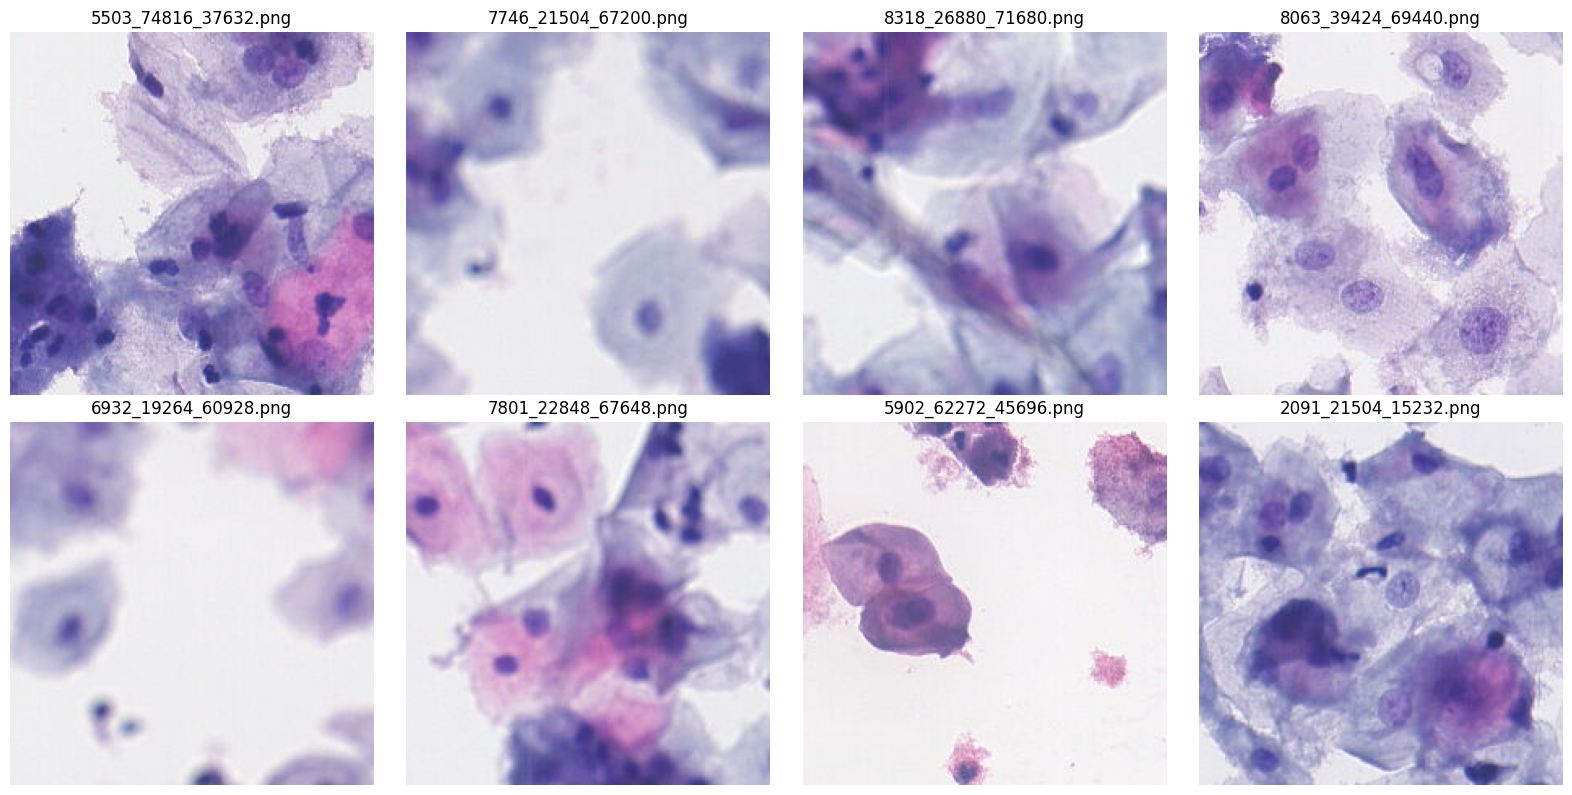

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for idx, ax in zip(a, axes.flat):
    filename = tiles_annotation.iloc[idx][0]
    img = Image.open(save_path + "/" + filename)

    ax.imshow(img)
    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Criando anotação para visualização via KFSlideOS

In [47]:
annotations = []

w = 448  # 224 px no nível 1 = 448 px no nível 0
for i,idx in enumerate(a):
  tile = str(tiles_annotation.iloc[idx][0]).split(".")[0]

  x_coord = int(tile.split("_")[1])
  y_coord = int(tile.split("_")[2])

  annotations.append({
      "guid": str(uuid.uuid4()), "name": f"tile_id {idx}",
              "description": f"Coords: x={x_coord} y={y_coord} // Predicted label (tile): {labels[np.array(logits_topk)[i].argmax()]} // Priority: {i+1} // Predicted label (slide): {labels[y.argmax().item()]}",
      "type": "Rectangle", "scale": 0.5, "width": 3, "color": 0xFF0000, "visible": True,
      "region": {"x": x_coord, "y": y_coord, "width": w, "height": w},
      "points": [{"x": x_coord, "y": y_coord}, {"x": x_coord + w, "y": y_coord}, {"x": x_coord, "y": y_coord + w}, {"x": x_coord + w, "y": y_coord + w}],
      "imageId": 0, "imageindex": 0, "isAllShow": False, "isAlwaysShowDesc": False,
      "fontUnderLine": False, "fontSize": 12, "fontFamily": "Arial", "fontItalic": False, "fontBold": False,
      "measurement": False, "radius": 0, "arcLength": 0, "angle": 0, "RectMarkCount": 0,
  })

out = Path(base_dir) / Path(f"Annotations/{slide_name}_kfb") / Path("Annotations") /"1.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(annotations))

5792